| Concept   | On regarde quoi ?      | Signification                      |
| --------- | ---------------------- | ---------------------------------- |
| SASA      | Surface brute (Å²)     | Surface accessible                 |
| rSASA     | Surface relative (0-1) | % exposition                       |
| Surface   | rSASAm > 0.25          | Résidu exposé                      |
| Interface | ΔrSASA > 0.01          | Résidu impliqué dans l’interaction |


In [35]:
import pickle
import pandas as pd

# 1- Importing docs

In [36]:
m1_file = "2FJU_AB_m1.pkl"
m2_file = "2FJU_AB_m2.pkl"
c_file  = "2FJU_AB_c.pkl"

d_m1 = pickle.load(open(m1_file, "rb"))
d_m2 = pickle.load(open(m2_file, "rb"))
d_c  = pickle.load(open(c_file,  "rb"))

In [55]:
print(d_m1.keys())
print(d_m1.values())
print(d_m1["B"].keys())
print(extract_residue_ids(d_m1["B"]))

dict_keys(['chains', 'B'])
dict_values([['B'], {'reslist': ['11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99', '100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '110', '111', '112', '113', '114', '115', '116', '117', '118', '119', '120', '121', '122', '123', '124', '125', '126', '127', '128', '129', '130', '131', '132', '133', '134', '135', '136', '137', '138', '139', '140', '141', '142', '143', '144', '145', '146', '147', '148', '149', '150', '151', '152', '153', '154', '155', '156', '157', 

# 2- Useful functions

In [38]:
def get_chain_keys(d):
    """Return chain keys (exclude 'chains' if present)."""
    return [k for k in d.keys() if k != "chains"]

def guess_chain_map(d_m, d_c, fallback_chain):
    """
    Try to guess the chain mapping between monomer and complex by matching chain keys.
    If no match is found, return the fallback chain.
    """
    m_chains = get_chain_keys(d_m)
    c_chains = get_chain_keys(d_c)

    if len(m_chains) == 0:
        raise ValueError("No chains found in monomer.")
    if len(c_chains) == 0:
        raise ValueError("No chains found in complex.")

    cm = m_chains[0]
    if cm in c_chains:
        return cm
    return fallback_chain

def extract_residue_ids(d_chain):
    """List of residue IDs (keys) excluding 'reslist' if present."""
    return [r for r in d_chain.keys() if r != "reslist"]

def build_table(d_m, d_c, chain_m, chain_c, monomer_name, thr_surface=0.25, thr_interface=0.01):
    """
    Build a DataFrame comparing residues in monomer and complex for given chains.
    Classify residues as surface and interface based on rSASA values and thresholds.
    """
    rows = []
    res_ids = extract_residue_ids(d_m[chain_m])

    for r in res_ids:
        #Security: skip if residue not in complex data
        if chain_c not in d_c or r not in d_c[chain_c]:
            continue

        rm = d_m[chain_m][r]
        rc = d_c[chain_c][r]
        
        rSASAm = rm.get("rSASA", None)
        SASAm  = rm.get("SASA", None)
        rSASAc = rc.get("rSASA", None)
        SASAc  = rc.get("SASA", None)

        # type of residue: try multiple keys, default to "NA"
        res_type = (rm.get("resname")
                    or rm.get("AA")
                    or rm.get("type")
                    or rm.get("name")
                    or "NA")

        # if rSASA is missing in either monomer or complex, skip this residue
        if rSASAm is None or rSASAc is None:
            continue

        delta = rSASAm - rSASAc
        is_surface   = (rSASAm > thr_surface)
        is_interface = (delta  > thr_interface)

        rows.append({
            "monomer": monomer_name,
            "chain_monomer": chain_m,
            "chain_complex": chain_c,
            "res_id": r,
            "res_type": res_type,
            "rSASAm": rSASAm,
            "SASAm": SASAm,
            "rSASAc": rSASAc,
            "SASAc": SASAc,
            "delta_rSASA": delta,
            "is_surface": is_surface,
            "is_interface": is_interface
        })

    return pd.DataFrame(rows)


# 3- Choosing chains

In [39]:
print("Monomère 1 chains:", get_chain_keys(d_m1))
print("Monomère 2 chains:", get_chain_keys(d_m2))
print("Complexe chains  :", get_chain_keys(d_c))

Monomère 1 chains: ['B']
Monomère 2 chains: ['A']
Complexe chains  : ['B', 'A']


In [ ]:
chain_c_m1 = guess_chain_map(d_m1, d_c, fallback_chain="A")
chain_c_m2 = guess_chain_map(d_m2, d_c, fallback_chain="B") # here the fulback is the opposite chain to see if the mapping didn't work

chain_m1 = get_chain_keys(d_m1)[0]
chain_m2 = get_chain_keys(d_m2)[0]

print("Mapping choisi:")
print("m1:", chain_m1, "-> complex:", chain_c_m1)
print("m2:", chain_m2, "-> complex:", chain_c_m2)


Mapping choisi:
m1: B -> complex: B
m2: A -> complex: A


# 4- Table construction

In [41]:
df1 = build_table(d_m1, d_c, chain_m1, chain_c_m1, monomer_name="m1")
df2 = build_table(d_m2, d_c, chain_m2, chain_c_m2, monomer_name="m2")

df = pd.concat([df1, df2], ignore_index=True)

In [42]:
df

,monomer,chain_monomer,chain_complex,res_id,res_type,rSASAm,SASAm,rSASAc,SASAc,delta_rSASA,is_surface,is_interface
0,m1,B,B,11,PRO,0.714692,98.062944,0.714692,98.062944,0.0,True,False
1,m1,B,B,12,LYS,0.919977,188.576870,0.919977,188.576870,0.0,True,False
2,m1,B,B,13,VAL,0.089422,13.589396,0.089422,13.589396,0.0,False,False
3,m1,B,B,14,LYS,0.554962,113.756053,0.554962,113.756053,0.0,True,False
4,m1,B,B,15,ALA,0.776759,84.480317,0.776759,84.480317,0.0,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
868,m2,A,A,173,ILE,0.000616,0.108192,0.000616,0.108192,0.0,False,False
869,m2,A,A,174,ARG,0.439235,104.612586,0.439235,104.612586,0.0,True,False
870,m2,A,A,175,ALA,0.293903,31.964839,0.293903,31.964839,0.0,True,False
871,m2,A,A,176,VAL,0.263810,40.091185,0.263810,40.091185,0.0,True,False


In [44]:
print(df["monomer"].unique())
print(df["chain_complex"].unique())
print(df["chain_monomer"].unique())


['m1' 'm2']
['B' 'A']
['B' 'A']


# 5- Results

In [ ]:
surface_df   = df[df["is_surface"]].copy() # ça donne que les valeurs True pour is_surface (faut comprendre python)
interface_df = df[df["is_interface"]].copy() # ça donne que les valeurs True pour is_interface

print("\n--- Resume ---")
print("Total résidus analysés:", len(df))
print("Résidus SURFACE:", len(surface_df))
print("Résidus INTERFACE:", len(interface_df))



--- Resume ---
Total résidus analysés: 873
Résidus SURFACE: 385
Résidus INTERFACE: 30


In [46]:
print("\nExample interface (top 10 par ΔrSASA):")
print(interface_df.sort_values("delta_rSASA", ascending=False).head(10)[["monomer","chain_complex","res_id","res_type","rSASAm","rSASAc","delta_rSASA"]])


Example interface (top 10 par ΔrSASA):
    monomer chain_complex res_id res_type    rSASAm    rSASAc  delta_rSASA
41       m1             B     52      GLN  0.842726  0.083270     0.759456
732      m2             A     37      PHE  0.676342  0.046556     0.629786
765      m2             A     70      LEU  0.747868  0.169540     0.578328
761      m2             A     66      ARG  0.924683  0.496743     0.427940
73       m1             B     84      VAL  0.617911  0.203646     0.414264
762      m2             A     67      LEU  0.591524  0.177354     0.414170
107      m1             B    118      TYR  0.533494  0.135010     0.398484
11       m1             B     22      ARG  0.601419  0.229888     0.371532
731      m2             A     36      VAL  0.578879  0.216553     0.362326
24       m1             B     35      PRO  0.366277  0.061732     0.304545


In [47]:
print("\nExample surface (top 10 par ΔrSASA):")
print(surface_df.sort_values("delta_rSASA", ascending=True).head(10)[["monomer","chain_complex","res_id","res_type","rSASAm","rSASAc","delta_rSASA"]])


Example surface (top 10 par ΔrSASA):
    monomer chain_complex res_id res_type    rSASAm    rSASAc  delta_rSASA
190      m1             B    201      GLU  0.730393  0.730393          0.0
843      m2             A    148      GLU  0.559326  0.559326          0.0
845      m2             A    150      GLY  0.618038  0.618038          0.0
847      m2             A    152      VAL  0.498934  0.498934          0.0
848      m2             A    153      LYS  0.482370  0.482370          0.0
855      m2             A    160      LEU  0.555809  0.555809          0.0
856      m2             A    161      THR  0.579682  0.579682          0.0
857      m2             A    162      GLN  0.294358  0.294358          0.0
858      m2             A    163      ARG  0.691034  0.691034          0.0
859      m2             A    164      GLY  0.343444  0.343444          0.0


In [88]:
interface_df["monomer"].unique()

array(['m1', 'm2'], dtype=object)

# 6- CSV

In [49]:
df.to_csv("all_residues_surface_interface.csv", index=False)
surface_df.to_csv("surface_residues.csv", index=False)
interface_df.to_csv("interface_residues.csv", index=False)

print("\nCSV générés:")
print("- all_residues_surface_interface.csv")
print("- surface_residues.csv")
print("- interface_residues.csv")


CSV générés:
- all_residues_surface_interface.csv
- surface_residues.csv
- interface_residues.csv


# 7- Activité 6

In [50]:
# total number of residus in surface and interface for m1 and m2
print("\nResidus SURFACE par monomère:")
print(surface_df.groupby("monomer").size())
print("\nResidus INTERFACE par monomère:")
print(interface_df.groupby("monomer").size())


Residus SURFACE par monomère:
monomer
m1    292
m2     93
dtype: int64

Residus INTERFACE par monomère:
monomer
m1    17
m2    13
dtype: int64


In [66]:
# taille en SASA pour surface et interface pour m1 et m2 
print("\nSASA  des résidus SURFACE par monomère:")
print(surface_df.groupby("monomer")["SASAm"].sum())
print("\nSASA  des résidus INTERFACE par monomère:")
print(interface_df.groupby("monomer")["SASAm"].sum())



SASA  des résidus SURFACE par monomère:
monomer
m1    24782.909652
m2     8442.858455
Name: SASAm, dtype: float64

SASA  des résidus INTERFACE par monomère:
monomer
m1    1388.748878
m2    1127.108194
Name: SASAm, dtype: float64


In [71]:
# nombre d'occurrences des 20 acides aminés 
print(list(surface_df["res_type"].value_counts()))
print(surface_df["res_type"].unique())


[54, 40, 38, 34, 24, 23, 22, 19, 19, 19, 18, 16, 12, 12, 12, 10, 7, 5, 1]
['PRO' 'LYS' 'ALA' 'TYR' 'SER' 'GLN' 'GLY' 'ARG' 'ASP' 'GLU' 'THR' 'VAL'
 'ILE' 'MET' 'PHE' 'ASN' 'LEU' 'HIS' 'TRP']


In [86]:
surface_df["res_type"].value_counts().sort_index()

res_type
ALA    16
ARG    19
ASN    19
ASP    38
GLN    18
GLU    40
GLY    19
HIS     7
ILE     5
LEU    22
LYS    54
MET    12
PHE    12
PRO    34
SER    23
THR    24
TRP     1
TYR    10
VAL    12
Name: count, dtype: int64

In [87]:
interface_df["res_type"].value_counts().sort_index()

res_type
ALA    1
ARG    2
ASN    3
ASP    3
GLN    1
ILE    2
LEU    2
LYS    3
PHE    2
PRO    1
SER    4
TRP    1
TYR    2
VAL    3
Name: count, dtype: int64

In [93]:
# pourcentage de residus par type (hydrophobe, polaire, chargé) pour interface et suraface 
hydrophobe = ["ALA","CYS","VAL","LEU","ILE","MET","PRO","PHE","TRP"]
polaire = ["SER","THR","ASN","GLN","GLY","TYR"]
charge = ["ASP","GLU","LYS","ARG","HIS"]
print("\nPourcentage de résidus hydrophobes, polaires et chargés dans les résidus de surface:")
surface_counts = surface_df["res_type"].value_counts()
surface_total = surface_counts.sum()
for res_type in ["hydrophobe", "polaire", "chargé"]:
    if res_type == "hydrophobe":
        count = surface_counts[surface_counts.index.isin(hydrophobe)].sum()
    elif res_type == "polaire":
        count = surface_counts[surface_counts.index.isin(polaire)].sum()
    elif res_type == "chargé":
        count = surface_counts[surface_counts.index.isin(charge)].sum()
    percentage = (count / surface_total) * 100 if surface_total > 0 else 0
    print(f"{res_type.capitalize()}: {percentage:.2f}%")
print("\nPourcentage de résidus hydrophobes, polaires et chargés dans les résidus d'interface:")
interface_counts = interface_df["res_type"].value_counts()
interface_total = interface_counts.sum()
for res_type in ["hydrophobe", "polaire", "chargé"]:
    if res_type == "hydrophobe":
        count = interface_counts[interface_counts.index.isin(hydrophobe)].sum()
    elif res_type == "polaire":
        count = interface_counts[interface_counts.index.isin(polaire)].sum()
    elif res_type == "chargé":
        count = interface_counts[interface_counts.index.isin(charge)].sum()
    percentage = (count / interface_total) * 100 if interface_total > 0 else 0
    print(f"{res_type.capitalize()}: {percentage:.2f}%")


Pourcentage de résidus hydrophobes, polaires et chargés dans les résidus de surface:
Hydrophobe: 29.61%
Polaire: 29.35%
Chargé: 41.04%

Pourcentage de résidus hydrophobes, polaires et chargés dans les résidus d'interface:
Hydrophobe: 40.00%
Polaire: 33.33%
Chargé: 26.67%


# Activité 7

In [99]:
import matplotlib.pyplot as plt
import pandas as pd

In [104]:
df = pd.read_csv("Activité 6 - Résultats - 6.1.csv",header=1)

In [111]:
df["groupe"] = df["groupe"].ffill()

In [112]:
df.columns = ["groupe", "monomère", "taille_surface", "taille_interface"]

In [113]:
df.head()

,groupe,monomère,taille_surface,taille_interface
0,0.0,m1,107.0,21.0
1,0.0,m2,356.0,25.0
2,1.0,m1,81.0,18.0
3,1.0,m2,99.0,20.0
4,2.0,m1,45.0,15.0


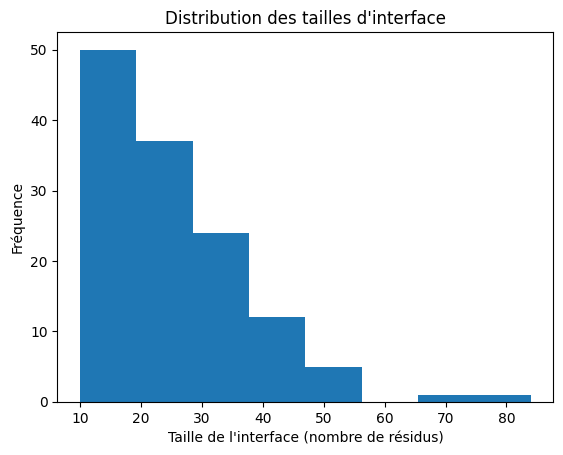

In [115]:
plt.figure()
plt.hist(df["taille_interface"].dropna(), bins=8)

plt.xlabel("Taille de l'interface (nombre de résidus)")
plt.ylabel("Fréquence")
plt.title("Distribution des tailles d'interface")

plt.show()

The distribution of interface sizes is right-skewed, with most interfaces ranging between 10 and 30 residues. A few larger interfaces are observed, including one outlier around 80 residues. The distribution is not symmetric and therefore does not follow a normal distribution, which is expected for biological size-related variables.

In [116]:
print("Moyenne :", df["taille_interface"].mean())
print("Médiane :", df["taille_interface"].median())
print("Écart-type :", df["taille_interface"].std())

Moyenne : 25.869230769230768
Médiane : 24.0
Écart-type : 12.167684014939656


In [117]:
df2 = pd.read_csv("Activité 6 - Résultats - 6.2.csv", header=1)
df2.columns = ["groupe", "monomere", "taille_surface", "taille_interface"]
df2["groupe"] = df2["groupe"].ffill()

In [118]:
df2.head()

,groupe,monomere,taille_surface,taille_interface
0,0.0,m1,10501.0,1929.0
1,0.0,m2,34918.0,1752.0
2,1.0,m1,7139.0,1814.0
3,1.0,m2,8657.0,1873.0
4,2.0,m1,3632.0,1147.0


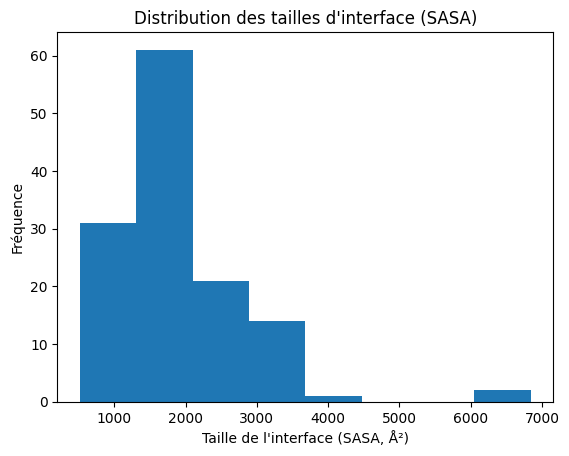

In [119]:
plt.figure()
plt.hist(df2["taille_interface"].dropna(), bins=8)

plt.xlabel("Taille de l'interface (SASA, Å²)")
plt.ylabel("Fréquence")
plt.title("Distribution des tailles d'interface (SASA)")

plt.show()

In [120]:
print("Moyenne :", df2["taille_interface"].mean())
print("Médiane :", df2["taille_interface"].median())
print("Écart-type :", df2["taille_interface"].std())

Moyenne : 1895.1787367846155
Médiane : 1661.5
Écart-type : 917.6876274657334


The distribution of interface sizes expressed in SASA (Å²) is positively skewed. Most interfaces range between 1000 and 2500 Å². The mean (≈1895 Å²) is higher than the median (≈1661 Å²), confirming the right-skewed distribution. A few large interfaces significantly increase the dispersion (SD ≈ 918 Å²). This variability is consistent with biological expectations, as protein-protein interfaces can vary considerably in size.

In [121]:
df["ratio_interface_surface"] = (df["taille_interface"] / df["taille_surface"])

In [122]:
df[["taille_surface", "taille_interface", "ratio_interface_surface"]].head()

,taille_surface,taille_interface,ratio_interface_surface
0,107.0,21.0,0.196262
1,356.0,25.0,0.070225
2,81.0,18.0,0.222222
3,99.0,20.0,0.202020
4,45.0,15.0,0.333333


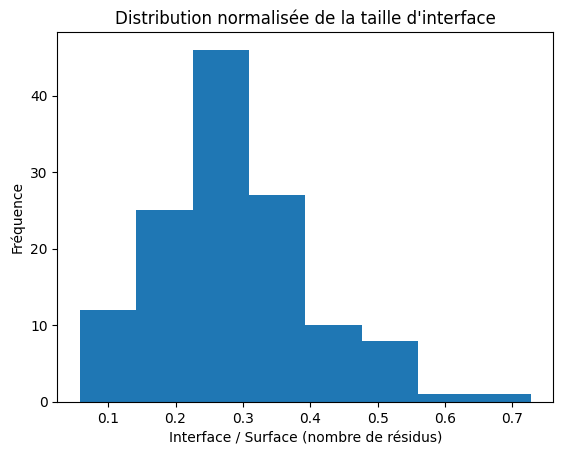

In [123]:
plt.figure()
plt.hist(df["ratio_interface_surface"].dropna(), bins=8)

plt.xlabel("Interface / Surface (nombre de résidus)")
plt.ylabel("Fréquence")
plt.title("Distribution normalisée de la taille d'interface")

plt.show()

In [124]:
print("Moyenne :", df["ratio_interface_surface"].mean())
print("Médiane :", df["ratio_interface_surface"].median())
print("Écart-type :", df["ratio_interface_surface"].std())

Moyenne : 0.28757083967285585
Médiane : 0.27793103448275863
Écart-type : 0.11649940583952338
